# Assignment 11: Decision Trees for Classification and Regression

In this assignment, I will build decision tree models for two health-related problems:
- Classification: predicting whether a patient has heart disease (sick or healthy), using the UCI Heart Disease dataset (Cleveland).
- Regression: predicting a person's yearly medical insurance costs, using the Medical Cost Personal dataset from Kaggle (insurance.csv).

I used these datasets instead of Wine and Linnerud (with my instructor's permission), because they are large enough to test how different hyperparameters change a decision tree, and they connect to the sick vs healthy example I used in class.

For each part, I will load and explore the data, split it into training and test sets, train a decision tree, evaluate it, visualize the tree, and then experiment with hyperparameters such as criterion (Gini vs entropy), max_depth, min_samples_split, min_samples_leaf, and ccp_alpha to understand how each one affects the model.

# Part 1: Decision Tree for Classification - Heart Disease

## Step 1: Load the Dataset and Split into Training and Test Sets

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error, mean_absolute_error, r2_score)


In [2]:
pd.set_option("display.max_columns", None)

In [3]:
# Load the Cleveland data (no header row, "?" means missing)
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
heart = pd.read_csv("processed.cleveland.data", header=None, names=cols, na_values="?")

In [4]:
# Binary target: 0 = healthy, 1 = sick (num 1 to 4)
heart["target"] = (heart["num"] > 0).astype(int)
heart = heart.drop(columns="num")

In [5]:

print("Shape:", heart.shape)

Shape: (303, 14)


In [6]:
print("Missing values:", heart.isnull().sum().sum())

Missing values: 6


In [7]:
print("Duplicate rows:", heart.duplicated().sum())

Duplicate rows: 0


In [8]:
print("\nTarget (0 = healthy, 1 = sick):")


Target (0 = healthy, 1 = sick):


In [9]:
print(heart["target"].value_counts())

target
0    164
1    139
Name: count, dtype: int64


In [10]:
display(heart.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [11]:
# Split 80/20
X_h = heart.drop(columns="target")
y_h = heart["target"]
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_h, y_h, test_size=0.2, random_state=42, stratify=y_h
)
print("\nX_train:", X_train_h.shape, "| X_test:", X_test_h.shape)


X_train: (242, 13) | X_test: (61, 13)


### Interpretation

The Cleveland Heart Disease dataset has 303 patients and 14 columns: 13 medical features and the target. I created a binary target where 0 means healthy (no heart disease) and 1 means sick (disease level 1 to 4), and removed the original disease level column to avoid data leakage.

- 164 patients are healthy (54%) and 139 are sick (46%), so the classes are fairly balanced.
- There are 6 missing values (in ca and thal), which I will fill using the training data.
- There are no duplicate rows.
- The first rows show that all features are numbers, but some are category codes, such as cp (chest pain type 1 to 4) and thal (3 = normal, 6 = fixed defect, 7 = reversible defect).

I split the data into 80% training (242 patients) and 20% testing (61 patients), using stratify to keep the same healthy/sick balance in both sets.

## Step 2: Explore the Training Data and Prepare It

In [12]:
train_h = X_train_h.copy()
train_h["target"] = y_train_h

In [13]:
# Summary statistics
display(train_h.describe().round(2))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,242.00,242.00,242.00,242.00,242.00,242.00,242.00,242.00,242.00,242.00,242.00,241.00,241.00,242.00
mean,54.55,0.68,3.15,130.96,249.84,0.14,0.98,149.96,0.33,1.00,1.59,0.61,4.71,0.46
std,9.00,0.47,0.98,17.62,52.85,0.35,1.00,22.69,0.47,1.12,0.61,0.88,1.95,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,2.25,120.00,212.00,0.00,0.00,134.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,244.50,0.00,0.00,153.50,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,277.75,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,1.00


In [14]:
# Missing values in train and test
print("Missing - train:", X_train_h.isnull().sum()[lambda s: s > 0].to_dict(),
      "| test:", X_test_h.isnull().sum()[lambda s: s > 0].to_dict())

Missing - train: {'ca': 1, 'thal': 1} | test: {'ca': 3, 'thal': 1}


C:\Users\patel\AppData\Local\Temp\ipykernel_26932\896898259.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Healthy", "Sick"])
C:\Users\patel\AppData\Local\Temp\ipykernel_26932\896898259.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Healthy", "Sick"])
C:\Users\patel\AppData\Local\Temp\ipykernel_26932\896898259.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Healthy", "Sick"])
C:\Users\patel\AppData\Local\Temp\ipykernel_26932\896898259.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Healthy", "Sick"])


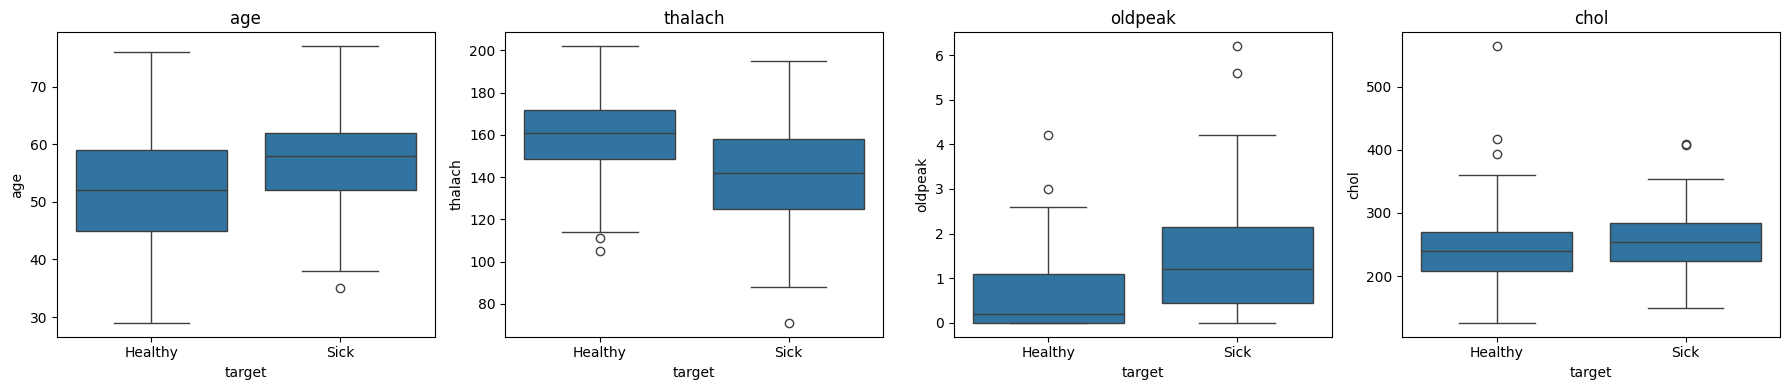

In [15]:
# Key features: sick vs healthy
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak", "chol"]):
    sns.boxplot(data=train_h, x="target", y=col, ax=ax)
    ax.set_xticklabels(["Healthy", "Sick"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [16]:
# Category features: % sick in each group
for col in ["cp", "thal", "exang"]:
    print(f"\n% sick by {col}:")
    print((train_h.groupby(col)["target"].mean() * 100).round(1))


% sick by cp:
cp
1.0    31.6
2.0    16.7
3.0    23.4
4.0    70.9
Name: target, dtype: float64

% sick by thal:
thal
3.0    21.5
6.0    63.6
7.0    77.9
Name: target, dtype: float64

% sick by exang:
exang
0.0    31.3
1.0    75.9
Name: target, dtype: float64


In [17]:
# Fill missing values using TRAINING data only
ca_median = X_train_h["ca"].median()
thal_mode = X_train_h["thal"].mode()[0]
for data in (X_train_h, X_test_h):
    data["ca"] = data["ca"].fillna(ca_median)
    data["thal"] = data["thal"].fillna(thal_mode)
print("\nMissing after filling - train:", X_train_h.isnull().sum().sum(), "| test:", X_test_h.isnull().sum().sum())


Missing after filling - train: 0 | test: 0


### Interpretation

Summary statistics (242 training patients):
- Patients are 29 to 77 years old (median 56), and about 68% are male.
- 46% of training patients are sick.
- Cholesterol ranges from 126 to 564, and maximum heart rate (thalach) from 71 to 202.

Sick vs healthy (boxplots):
- Sick patients tend to be older (median age about 58 vs 52).
- Sick patients have a lower maximum heart rate (median about 142 vs 161).
- Sick patients have higher oldpeak (ST depression during exercise), with a median of about 1.2 vs 0.2.
- Cholesterol is only slightly higher for sick patients, so it may not be very useful for splitting.

Percentage sick by category:
- Chest pain type 4 (asymptomatic): 70.9% sick, compared to 16.7% to 31.6% for the other types.
- thal 7 (reversible defect): 77.9% sick, and thal 6 (fixed defect): 63.6% sick, compared to 21.5% for thal 3 (normal).
- Exercise-induced chest pain (exang = 1): 75.9% sick, compared to 31.3% without it.

These features already separate sick and healthy patients well, so a decision tree is likely to use them for its first splits.

Missing values:
Training had 1 missing value in ca and 1 in thal, and the test set had 3 in ca and 1 in thal. I filled them with the median of ca and the mode of thal, both calculated from the training data only.

No scaling or one-hot encoding is needed, because decision trees split on threshold values and can work directly with the category codes.

## Steps 3 to 6: Build, Evaluate, and Visualize a Baseline Decision Tree

In [18]:
# Step 3: baseline tree with default settings
tree_default = DecisionTreeClassifier(random_state=42)
tree_default.fit(X_train_h, y_train_h)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [19]:
# Step 4: predictions
y_pred_h = tree_default.predict(X_test_h)

In [20]:
# Step 5: evaluation
print("Train accuracy:", round(accuracy_score(y_train_h, tree_default.predict(X_train_h)), 3))
print("Test accuracy: ", round(accuracy_score(y_test_h, y_pred_h), 3))
print("Tree depth:", tree_default.get_depth(), "| Number of leaves:", tree_default.get_n_leaves())
print("\n", classification_report(y_test_h, y_pred_h, target_names=["Healthy", "Sick"]))

Train accuracy: 1.0
Test accuracy:  0.738
Tree depth: 11 | Number of leaves: 48

               precision    recall  f1-score   support

     Healthy       0.81      0.67      0.73        33
        Sick       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61



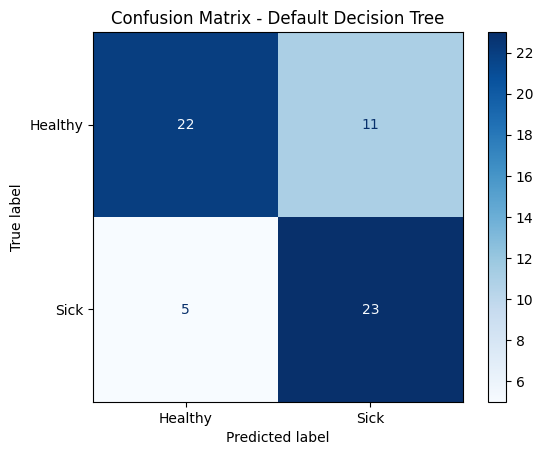

In [21]:
ConfusionMatrixDisplay(confusion_matrix(y_test_h, y_pred_h),
                       display_labels=["Healthy", "Sick"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Default Decision Tree")
plt.show()


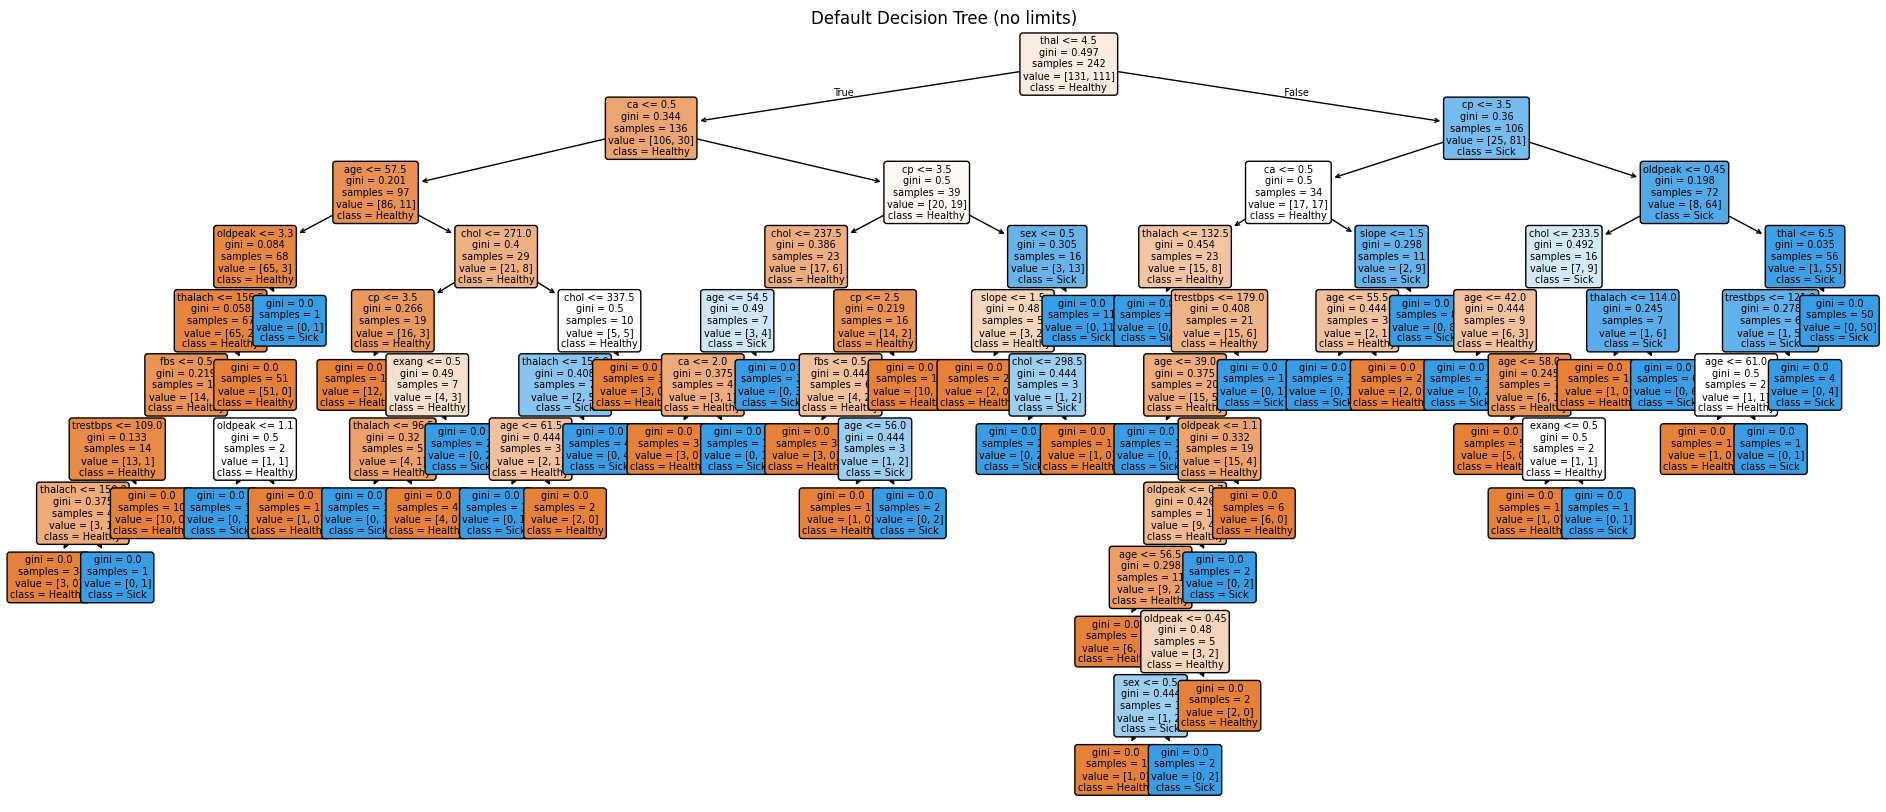

In [22]:
# Step 6: visualize the tree
plt.figure(figsize=(24, 10))
plot_tree(tree_default, feature_names=X_train_h.columns, class_names=["Healthy", "Sick"],
          filled=True, rounded=True, fontsize=7)
plt.title("Default Decision Tree (no limits)")
plt.show()

### Interpretation

Baseline model:
I trained a decision tree with the default settings (Gini criterion, no depth limit, minimum 1 sample per leaf). The tree grew to a depth of 11 with 48 leaves.

Overfitting:
- Training accuracy is 100% and test accuracy is 73.8%.
- The tree kept splitting until every leaf was pure, so many leaves contain only 1 or 2 patients. It memorized the training data instead of learning general patterns. This is clear overfitting.

Confusion matrix (61 test patients):
- 22 healthy patients were correctly predicted as healthy, and 23 sick patients were correctly predicted as sick.
- 11 healthy patients were wrongly predicted as sick (false alarms).
- 5 sick patients were wrongly predicted as healthy (missed cases). This is the most serious mistake in a medical setting.

Classification report:
- Healthy: precision 0.81 (when the model says healthy, it is right 81% of the time) and recall 0.67 (it found 22 of the 33 truly healthy patients).
- Sick: precision 0.68 (when it says sick, it is right 68% of the time) and recall 0.82 (it found 23 of the 28 truly sick patients).

The tree diagram:
- The first question (root node) is thal <= 4.5, which separates patients with a normal thal result from those with a defect. This matches the EDA, where thal 6 and 7 had 64% to 78% sick patients.
- The next splits use ca (number of blocked vessels) and cp (chest pain type), which were also strong in the EDA.
- Lower down, the tree becomes very deep and complex, with many tiny leaves (samples = 1 or 2). These small leaves are pure (gini = 0.0), but they are based on single patients, so they do not generalize to new patients.

Next, I will tune the hyperparameters to make the tree simpler and reduce overfitting.

## Step 7: Hyperparameter Experiments

I changed one hyperparameter at a time, keeping the others at their default values, to see how each one affects the tree. I judged the results mainly by 5-fold cross-validation accuracy on the training data, because the test set has only 61 patients.

In [23]:
from sklearn.model_selection import StratifiedKFold

In [24]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [33]:
def test_param(param, values, base=None):
    rows = []
    for v in values:
        settings = dict(base or {})
        settings[param] = v
        tree = DecisionTreeClassifier(random_state=42, **settings)
        tree.fit(X_train_h, y_train_h)
        rows.append({
            param: v,
            "Train acc": round(accuracy_score(y_train_h, tree.predict(X_train_h)), 3),
            "CV acc": round(cross_val_score(tree, X_train_h, y_train_h, cv=cv5).mean(), 3),
            "Test acc": round(accuracy_score(y_test_h, tree.predict(X_test_h)), 3),
            "Depth": tree.get_depth(),
            "Leaves": tree.get_n_leaves()
        })
    return pd.DataFrame(rows)


In [34]:
def plot_param(df, param, title):
    # Turn every value into a clean text label; None/NaN becomes "None"
    labels = []
    for v in df[param]:
        if pd.isna(v):
            labels.append("None")
        elif isinstance(v, float) and v.is_integer():
            labels.append(str(int(v)))      # 4.0 -> "4"
        else:
            labels.append(str(v))

    plt.figure(figsize=(8, 4))
    plt.plot(labels, df["Train acc"], marker="o", label="Train")
    plt.plot(labels, df["CV acc"], marker="o", label="Cross-validation")
    plt.xlabel(param)
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [35]:
# Criterion: unlimited trees, and the same comparison with max_depth=4
print("Criterion with no limits:")
print(test_param("criterion", ["gini", "entropy", "log_loss"]).to_string(index=False))
print("\nCriterion with max_depth=4:")
print(test_param("criterion", ["gini", "entropy", "log_loss"], base={"max_depth": 4}).to_string(index=False))


Criterion with no limits:
criterion  Train acc  CV acc  Test acc  Depth  Leaves
     gini        1.0   0.698     0.738     11      48
  entropy        1.0   0.715     0.803     10      48
 log_loss        1.0   0.715     0.803     10      48

Criterion with max_depth=4:
criterion  Train acc  CV acc  Test acc  Depth  Leaves
     gini      0.880   0.723     0.787      4      16
  entropy      0.868   0.785     0.787      4      14
 log_loss      0.868   0.785     0.787      4      14


### Interpretation: Criterion (Gini vs Entropy vs Log Loss)

The criterion decides how the tree measures impurity when choosing the best split.

With no limits:
- All three trees reached 100% training accuracy, because they kept splitting until every leaf was pure (overfitting).
- Entropy had a slightly higher cross-validation accuracy (71.5%) than Gini (69.8%).

With max_depth = 4:
- Entropy performed clearly better in cross-validation (78.5%) than Gini (72.3%), with a smaller gap between training and cross-validation accuracy, so it overfit less.
- Entropy also built a slightly simpler tree (14 leaves vs 16 for Gini).

log_loss gave exactly the same results as entropy. In scikit-learn, log_loss and entropy are the same calculation, just with different names.

In this dataset, entropy chose slightly better splits than Gini. Usually the two criteria give similar results, so the difference is small and may depend on this particular dataset.

 max_depth  Train acc  CV acc  Test acc  Depth  Leaves
       1.0      0.773   0.760     0.721      1       2
       2.0      0.773   0.723     0.770      2       4
       3.0      0.843   0.773     0.869      3       8
       4.0      0.880   0.723     0.787      4      16
       5.0      0.926   0.739     0.787      5      27
       6.0      0.959   0.694     0.820      6      36
       8.0      0.992   0.698     0.820      8      45
      10.0      0.996   0.698     0.787     10      47
       NaN      1.000   0.698     0.738     11      48


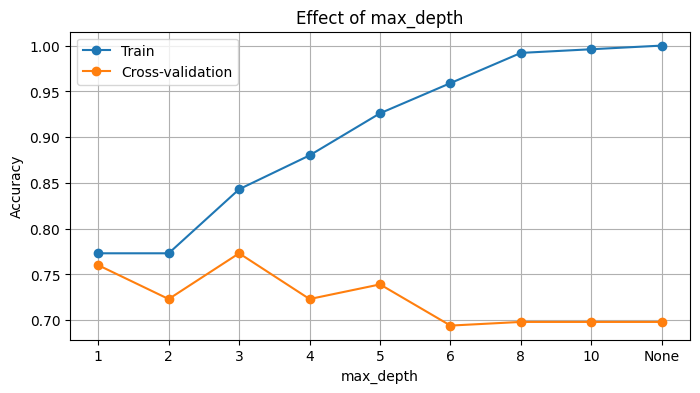

In [36]:
depth_df = test_param("max_depth", [1, 2, 3, 4, 5, 6, 8, 10, None])
print(depth_df.to_string(index=False))
plot_param(depth_df, "max_depth", "Effect of max_depth")

### Interpretation: max_depth

max_depth limits how many levels of questions the tree can ask.

- Training accuracy rises steadily as depth increases, from 77.3% at depth 1 to 100% with no limit (None), because deeper trees can memorize more of the training data.
- Cross-validation accuracy does not keep rising. It is highest at depth 3 (77.3%) and drops to about 69.8% for deep trees (depth 6 and above).
- The gap between the two lines grows with depth: at depth 3 the gap is about 7%, but with no limit it is about 30%. This shows overfitting getting worse.
- Even with depth 1 (just one question and 2 leaves), the tree reaches 76% cross-validation accuracy, because the first split on thal already separates sick and healthy patients well.
- Depth 3 gives the best balance: a simple tree with only 8 leaves that generalizes well (86.9% on the test set).

This is the classic pattern: too shallow can underfit, and too deep overfits. The best tree is in between.


 min_samples_leaf  Train acc  CV acc  Test acc  Depth  Leaves
                1      1.000   0.698     0.738     11      48
                2      0.942   0.711     0.770      9      38
                5      0.884   0.736     0.721      6      22
               10      0.843   0.789     0.869      4      13
               15      0.843   0.752     0.836      4      10
               20      0.773   0.744     0.770      4       8
               30      0.773   0.756     0.770      4       7
               40      0.773   0.760     0.721      3       5


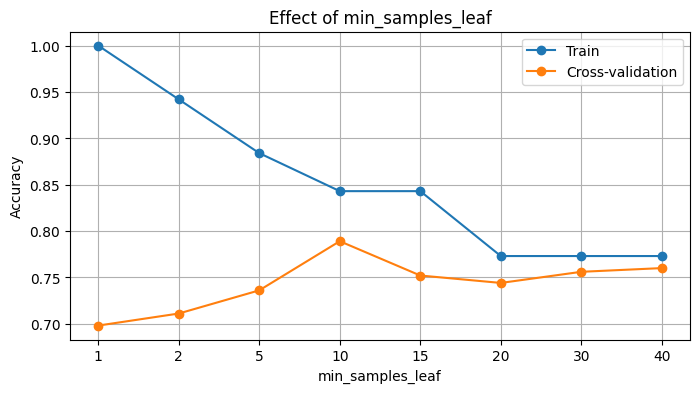

In [37]:
leaf_df = test_param("min_samples_leaf", [1, 2, 5, 10, 15, 20, 30, 40])
print(leaf_df.to_string(index=False))
plot_param(leaf_df, "min_samples_leaf", "Effect of min_samples_leaf")

### Interpretation: min_samples_leaf

min_samples_leaf sets the minimum number of patients allowed in each final leaf.

- With min_samples_leaf = 1 (the default), the tree has 48 leaves, 100% training accuracy, and only 69.8% cross-validation accuracy, because many leaves contain just one patient.
- As the minimum increases, the tree becomes smaller (from 48 leaves down to 5), and training accuracy falls, but cross-validation accuracy improves.
- The best result is min_samples_leaf = 10: cross-validation accuracy of 78.9%, the highest of all experiments, with a depth of 4 and 13 leaves. It also scored 86.9% on the test set.
- Above 10, cross-validation accuracy drops slightly (about 74% to 76%), because the leaves become too large to capture useful patterns.

This setting works like my "no 1-patient rooms" rule. Requiring at least 10 patients per leaf forces the tree to learn patterns shared by groups of patients instead of memorizing individuals.

 min_samples_split  Train acc  CV acc  Test acc  Depth  Leaves
                 2      1.000   0.698     0.738     11      48
                 5      0.959   0.744     0.787     10      38
                10      0.909   0.739     0.754      9      27
                20      0.868   0.715     0.820      6      16
                40      0.777   0.711     0.770      5       9
                60      0.777   0.723     0.770      5       8
                80      0.773   0.723     0.770      3       5


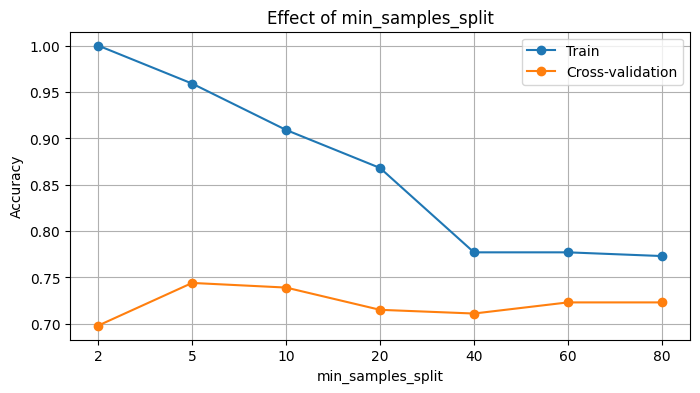

In [38]:
split_df = test_param("min_samples_split", [2, 5, 10, 20, 40, 60, 80])
print(split_df.to_string(index=False))
plot_param(split_df, "min_samples_split", "Effect of min_samples_split")

### Interpretation: min_samples_split

min_samples_split sets the minimum number of patients a node must have before it is allowed to split.

- With the default (2), the tree overfits: 100% training accuracy but only 69.8% cross-validation accuracy.
- Increasing it to 5 gave the best cross-validation accuracy (74.4%), and it stayed around 72% to 74% for larger values.
- As the value increases, the tree shrinks from 48 leaves to 5, and training accuracy drops from 100% to 77%.

min_samples_split helped less than min_samples_leaf. This is because it only stops large groups from splitting, but a split can still create a very small leaf. For example, a group of 20 patients could still split into 19 and 1. min_samples_leaf directly prevents these tiny leaves.

### Summary of the Experiments

- Every limit I added reduced overfitting compared to the default tree, which scored 100% on training data but only 69.8% in cross-validation.
- The most helpful single settings were min_samples_leaf = 10 (78.9% cross-validation accuracy), entropy with max_depth = 4 (78.5%), and max_depth = 3 (77.3%).
- The cross-validation results go up and down a little between values, because each fold only has about 48 patients. Small differences of 1% to 2% should not be over-interpreted.
- Next, I will try pruning with ccp_alpha and use GridSearchCV to find the best combination of these settings.

max_features  Train acc  CV acc  Test acc  Depth  Leaves
        None        1.0   0.698     0.738     11      48
        sqrt        1.0   0.694     0.770     12      75
        log2        1.0   0.694     0.770     12      75
         0.5        1.0   0.694     0.803     10      52


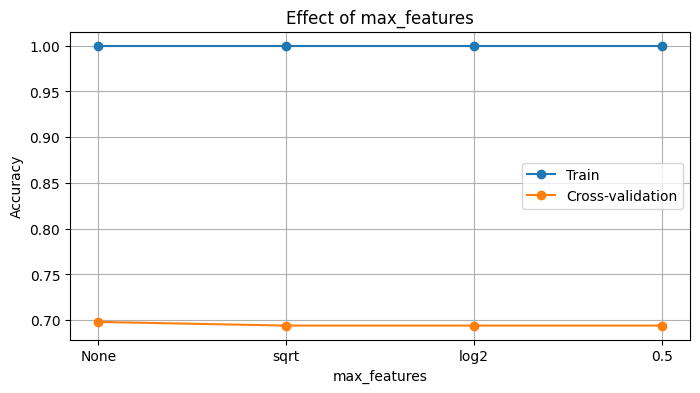

In [39]:
feat_df = test_param("max_features", [None, "sqrt", "log2", 0.5])
print(feat_df.to_string(index=False))
plot_param(feat_df, "max_features", "Effect of max_features")

### Interpretation: max_features

max_features controls how many features the tree is allowed to consider at each split.

- All four options reached 100% training accuracy, because the trees had no depth or leaf limits and still overfit.
- Cross-validation accuracy stayed about the same (69.4% to 69.8%), so limiting the features did not improve the model.
- With sqrt and log2 (about 3 random features per split), the tree grew larger (75 leaves vs 48). Because it could not always choose the best question, it needed more splits to separate the patients.

Limiting features on its own does not help a single tree here. Its main use is in Random Forests, where each tree sees different random features, which makes the trees different from each other and improves the combined result.

In [40]:
weight_df = test_param("class_weight", [None, "balanced"], base={"min_samples_leaf": 10})
print(weight_df.to_string(index=False))

class_weight  Train acc  CV acc  Test acc  Depth  Leaves
         NaN      0.843   0.789     0.869      4      13
    balanced      0.843   0.752     0.836      4      13


### Interpretation: class_weight

I tested class_weight with min_samples_leaf = 10 (the best setting from 7C). None means the default, where both classes count equally.

- Default (None): cross-validation accuracy of 78.9% and test accuracy of 86.9%.
- balanced: cross-validation accuracy dropped to 75.2% and test accuracy to 83.6%.

Balancing the classes made the model worse. The dataset is already close to balanced (46% sick and 54% healthy), so giving extra weight to the sick class was not needed and slightly changed the splits for the worse. class_weight="balanced" is more useful when one class is much rarer, such as fraud detection.

### 7G: Post-Pruning with ccp_alpha

Number of alpha values to test: 24


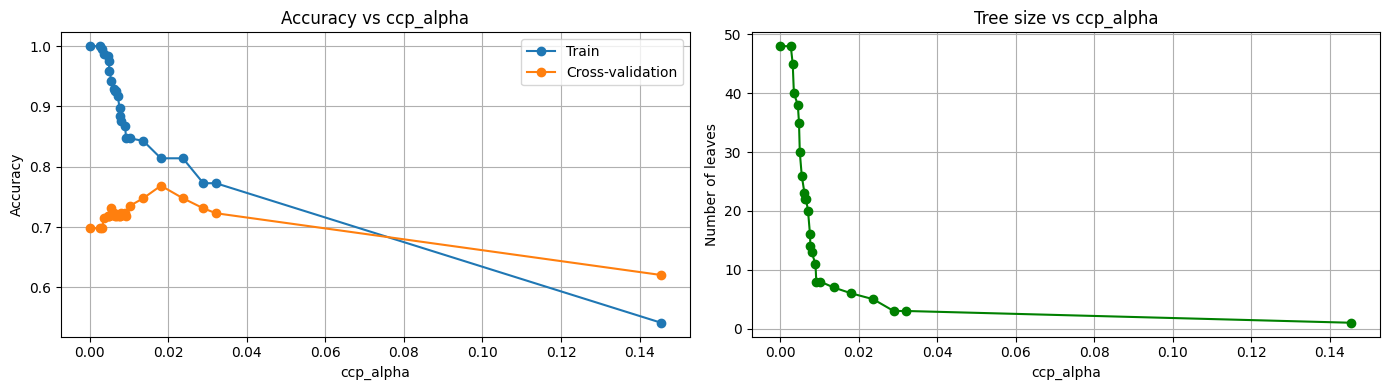

Best ccp_alpha: 0.0181 | CV acc: 0.769 | Leaves: 6


In [43]:
# Grow a full tree, then get the list of alpha values where branches get removed
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train_h, y_train_h)
alphas = np.unique(path.ccp_alphas.round(4))
print("Number of alpha values to test:", len(alphas))

rows = []
for a in alphas:
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a).fit(X_train_h, y_train_h)
    rows.append({
        "ccp_alpha": a,
        "Train acc": accuracy_score(y_train_h, t.predict(X_train_h)),
        "CV acc": cross_val_score(t, X_train_h, y_train_h, cv=cv5).mean(),
        "Leaves": t.get_n_leaves()
    })
alpha_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(alpha_df["ccp_alpha"], alpha_df["Train acc"], marker="o", label="Train")
axes[0].plot(alpha_df["ccp_alpha"], alpha_df["CV acc"], marker="o", label="Cross-validation")
axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy vs ccp_alpha"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(alpha_df["ccp_alpha"], alpha_df["Leaves"], marker="o", color="green")
axes[1].set_xlabel("ccp_alpha"); axes[1].set_ylabel("Number of leaves")
axes[1].set_title("Tree size vs ccp_alpha"); axes[1].grid(True)
plt.tight_layout()
plt.show()

best = alpha_df.loc[alpha_df["CV acc"].idxmax()]
print(f"Best ccp_alpha: {best['ccp_alpha']:.4f} | CV acc: {best['CV acc']:.3f} | Leaves: {int(best['Leaves'])}")

### Interpretation: Post-Pruning with ccp_alpha

Cost complexity pruning first grows the full tree and then removes the branches that add the least value. A larger ccp_alpha removes more branches. scikit-learn calculated 24 possible alpha values for this tree.

- At ccp_alpha = 0, there is no pruning: the tree has 48 leaves, 100% training accuracy, and about 70% cross-validation accuracy (overfitting).
- As alpha increases, branches are removed quickly. The number of leaves drops from 48 to about 8 by alpha = 0.01.
- The best result was ccp_alpha = 0.0181, with a cross-validation accuracy of 76.9% and only 6 leaves.
- At the largest alpha (0.145), the tree is pruned down to a single leaf, so it predicts "healthy" for everyone. Training accuracy falls to 54% (the share of healthy patients) and cross-validation to about 62%. This is underfitting.

Pre-pruning vs post-pruning:
Pre-pruning with min_samples_leaf = 10 gave a slightly higher cross-validation accuracy (79.7% with 13 leaves) than post-pruning (76.9% with 6 leaves). However, the pruned tree is even smaller and easier to explain. Both methods show the same idea: a simpler tree generalizes better than a fully grown one.

### 7H: Finding the Best Combination with GridSearchCV

In [41]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_leaf": [1, 5, 10, 15, 20],
    "min_samples_split": [2, 10, 20],
    "class_weight": [None, "balanced"]
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                    cv=cv5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_h, y_train_h)

print("Combinations tested:", len(grid.cv_results_["params"]))
print("Best settings:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))

# Top 5 combinations
top5 = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score").head(5)
print(top5[["params", "mean_test_score"]].to_string(index=False))

Combinations tested: 300
Best settings: {'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV accuracy: 0.797
                                                                                                            params  mean_test_score
      {'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 10}         0.797449
       {'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}         0.797449
      {'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 20}         0.797449
{'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 10, 'min_samples_split': 10}         0.797449
 {'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 10, 'min_samples_split': 2}         0.797449


### Interpretation: GridSearchCV

I used GridSearchCV to test 300 combinations of criterion, max_depth, min_samples_leaf, min_samples_split, and class_weight, using 5-fold cross-validation on the training data.

Best settings: criterion = gini, max_depth = 4, min_samples_leaf = 10, min_samples_split = 2, and class_weight = None.
Best cross-validation accuracy: 79.7%, compared to 69.8% for the default tree.

The top 5 combinations all scored exactly the same (79.7%). They all have min_samples_leaf = 10, which shows this is the most important setting:
- min_samples_split (2, 10, or 20) made no difference, because once every leaf must have at least 10 patients, any split already needs at least 20 patients.
- Gini and entropy tied, so the choice of criterion matters much less once the tree size is controlled.
- max_depth = 4 and max_depth = None tied, because with at least 10 patients per leaf, the tree naturally stops at about depth 4.

When several settings perform the same, it is best to choose the simplest one, so I chose the tree with max_depth = 4 and min_samples_leaf = 10.

## Step 8: Evaluating the Final Tuned Tree

       Model  Train acc  Test acc  Depth  Leaves
Default tree      1.000     0.738     11      48
  Tuned tree      0.843     0.869      4      13

               precision    recall  f1-score   support

     Healthy       0.88      0.88      0.88        33
        Sick       0.86      0.86      0.86        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



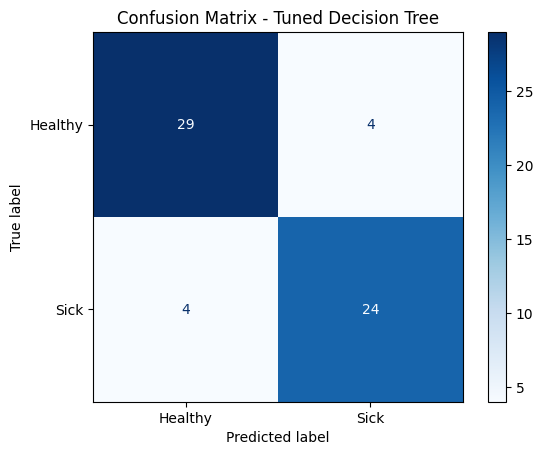

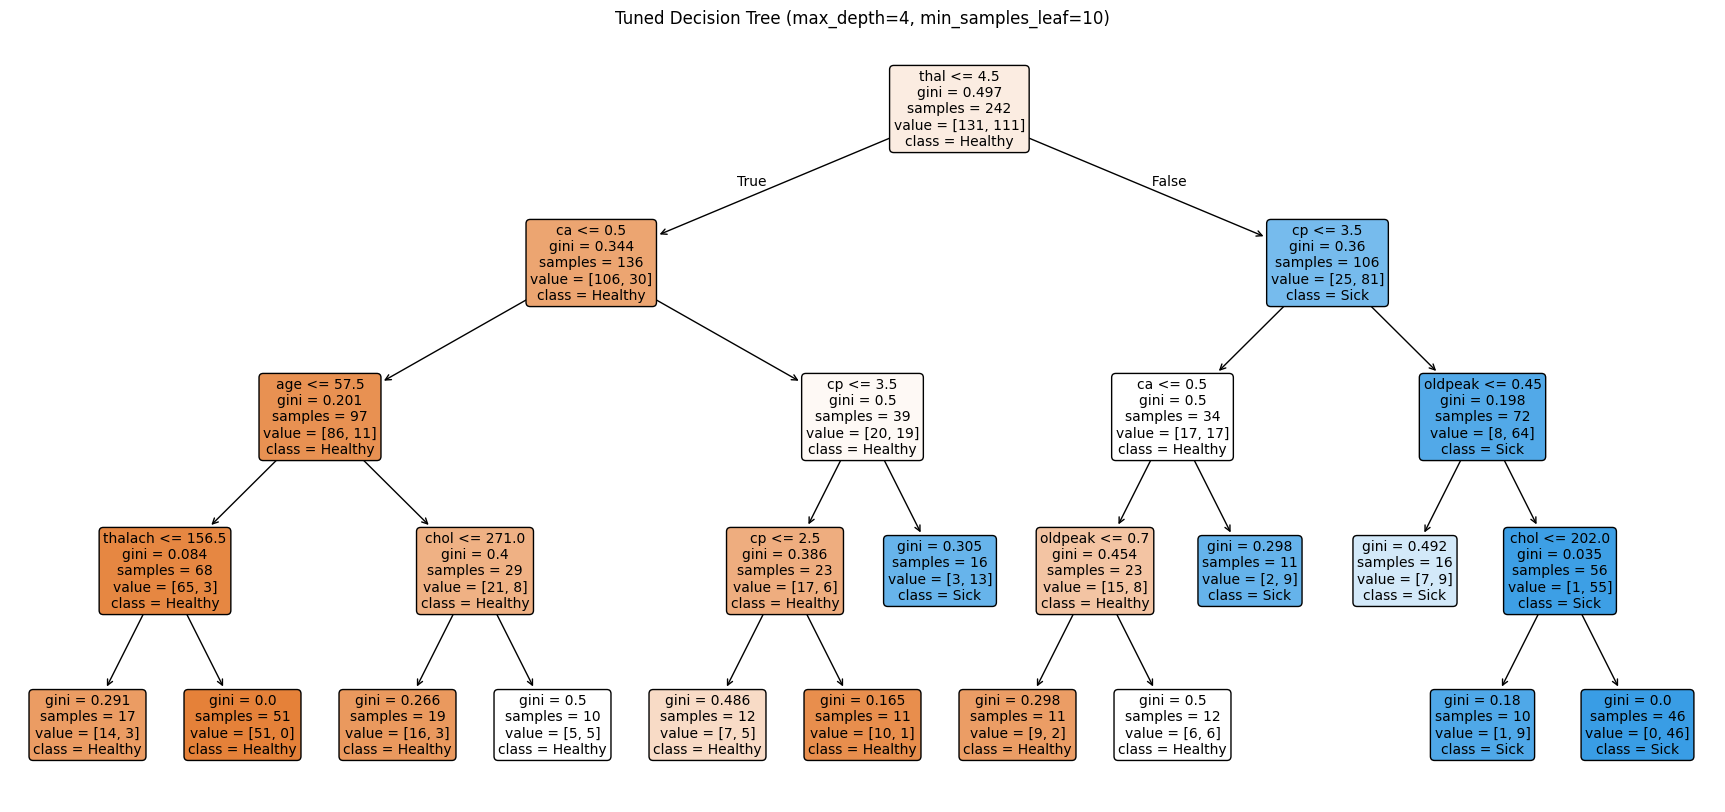

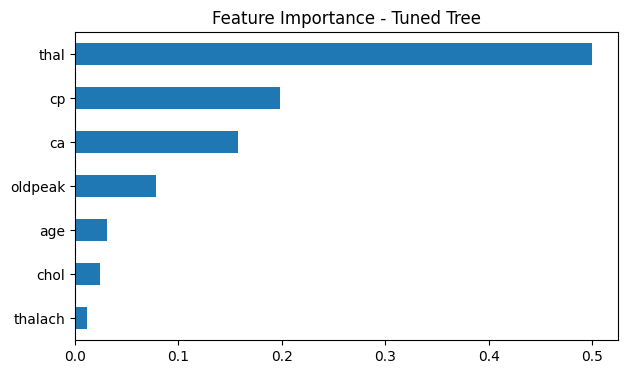

In [42]:
best_tree = grid.best_estimator_
y_pred_best = best_tree.predict(X_test_h)

# Compare default vs tuned
compare = pd.DataFrame([
    {"Model": "Default tree", "Train acc": accuracy_score(y_train_h, tree_default.predict(X_train_h)),
     "Test acc": accuracy_score(y_test_h, y_pred_h), "Depth": tree_default.get_depth(), "Leaves": tree_default.get_n_leaves()},
    {"Model": "Tuned tree", "Train acc": accuracy_score(y_train_h, best_tree.predict(X_train_h)),
     "Test acc": accuracy_score(y_test_h, y_pred_best), "Depth": best_tree.get_depth(), "Leaves": best_tree.get_n_leaves()}
]).round(3)
print(compare.to_string(index=False))

print("\n", classification_report(y_test_h, y_pred_best, target_names=["Healthy", "Sick"]))
ConfusionMatrixDisplay(confusion_matrix(y_test_h, y_pred_best),
                       display_labels=["Healthy", "Sick"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Tuned Decision Tree")
plt.show()

# The tuned tree (much smaller, readable)
plt.figure(figsize=(22, 10))
plot_tree(best_tree, feature_names=X_train_h.columns, class_names=["Healthy", "Sick"],
          filled=True, rounded=True, fontsize=10)
plt.title("Tuned Decision Tree (max_depth=4, min_samples_leaf=10)")
plt.show()

# Which features does the tree use most?
importance = pd.Series(best_tree.feature_importances_, index=X_train_h.columns).sort_values()
importance[importance > 0].plot(kind="barh", figsize=(7, 4), title="Feature Importance - Tuned Tree")
plt.show()

### Interpretation: Final Tuned Tree

Default vs tuned:
- The tuned tree (max_depth = 4, min_samples_leaf = 10) has 13 leaves instead of 48, and a depth of 4 instead of 11.
- Training accuracy dropped from 100% to 84.3%, because the tree no longer memorizes individual patients.
- Test accuracy improved from 73.8% to 86.9%. The tuned tree is simpler and also more accurate on new patients, which shows that the default tree was overfitting.

Confusion matrix (61 test patients):
- 29 healthy and 24 sick patients were classified correctly (53 of 61).
- 4 healthy patients were wrongly predicted as sick (down from 11 with the default tree).
- 4 sick patients were wrongly predicted as healthy (down from 5). These missed cases are still the most serious mistakes.

Classification report:
- Healthy: precision 0.88 and recall 0.88.
- Sick: precision 0.86 and recall 0.86, meaning the model found 24 of the 28 sick patients.
- Both classes are now predicted equally well.

The tree diagram:
- The first question is thal <= 4.5, which splits patients with a normal thal result (left, mostly healthy) from those with a defect (right, mostly sick).
- On the healthy side, the tree then asks about ca (number of blocked vessels) and age.
- On the sick side, it asks about cp (chest pain type) and oldpeak (ST depression during exercise).
- Each leaf now has at least 10 patients, so every rule is based on a group of patients rather than one person. For example, patients with a thal defect, chest pain type 4, and high oldpeak end up in leaves that are almost all sick.

Feature importance:
- thal is by far the most important feature (about 0.5), followed by cp (about 0.2) and ca (about 0.16). oldpeak, age, chol, and thalach have smaller roles.
- This matches the EDA, where thal, chest pain type, and blocked vessels showed the biggest differences between sick and healthy patients.
- The tree used only 7 of the 13 features. The others did not help separate the patients enough to be chosen.

# Part 2: Decision Tree for Regression - Medical Insurance Costs

## Step 1: Load the Dataset and Check Its Structure

In [46]:
ins = pd.read_csv("insurance.csv")
print("Shape:", ins.shape)

Shape: (1338, 7)


In [47]:
display(ins.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [49]:
print("\nData types:")
print(ins.dtypes)



Data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


In [50]:
print("\nUnique values:")
print(ins.nunique())


Unique values:
age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64


In [51]:
print("\nMissing values:", ins.isnull().sum().sum())
print("Duplicate rows:", ins.duplicated().sum())



Missing values: 0
Duplicate rows: 1


### Interpretation

The Medical Insurance dataset has 1,338 people and 7 columns. The target is charges, the yearly medical costs billed by health insurance, in dollars.

Features:
- age (18 to 64, as numbers), bmi (body mass index), and children (number of children covered, 0 to 5)
- sex (female or male), smoker (yes or no), and region (4 regions of the United States). These three are text, so they will need to be converted into numbers, because scikit-learn's decision tree only accepts numeric inputs.

Structure checks:
- There are no missing values.
- There is 1 duplicate row, which I will remove before splitting so the same person cannot appear in both the training and test sets.
- The first rows already show a big difference in costs: the 19-year-old smoker has charges of about $16,885, while the 18-year-old non-smoker has about $1,726.

## Step 2: Remove Duplicates, Split the Data, and Explore the Training Data

In [52]:
# Remove the duplicate before splitting
ins = ins.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", ins.shape)

Shape after removing duplicates: (1337, 7)


In [53]:
# Split 80/20
X_i = ins.drop(columns="charges")
y_i = ins["charges"]
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_i, y_i, test_size=0.2, random_state=42)
print("X_train:", X_train_i.shape, "| X_test:", X_test_i.shape)

X_train: (1069, 6) | X_test: (268, 6)


In [54]:
# EDA on training data
train_i = X_train_i.copy()
train_i["charges"] = y_train_i
display(train_i.describe().round(2))

,age,bmi,children,charges
count,1069.0,1069.00,1069.00,1069.00
mean,39.2,30.54,1.08,13030.20
std,14.0,6.05,1.19,11706.53
min,18.0,15.96,0.00,1121.87
25%,27.0,26.18,0.00,4747.05
50%,39.0,30.20,1.00,9290.14
75%,51.0,34.43,2.00,16450.89
max,64.0,53.13,5.00,62592.87



Average charges by sex:
        count     mean  median
sex                           
female    519  12305.0  9411.0
male      550  13714.0  9289.0

Average charges by smoker:
        count     mean   median
smoker                         
no        855   8498.0   7348.0
yes       214  31136.0  33392.0

Average charges by region:
           count     mean  median
region                           
northeast    253  13241.0  9876.0
northwest    264  11907.0  8749.0
southeast    287  14555.0  9059.0
southwest    265  12296.0  8968.0


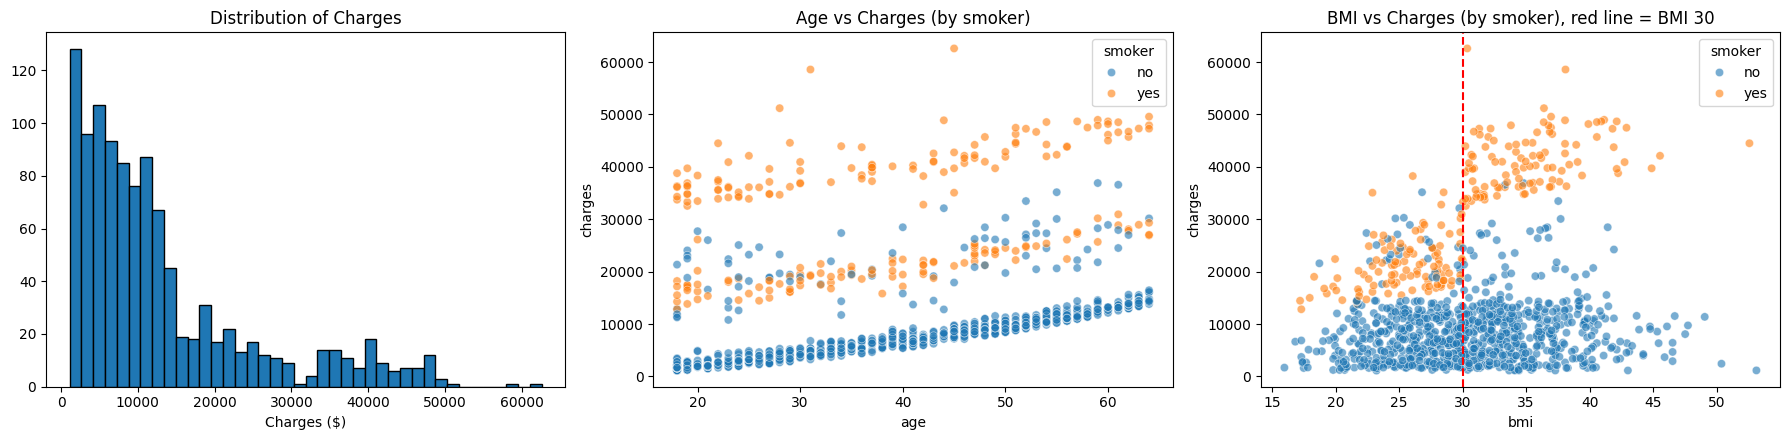

In [55]:
for col in ["sex", "smoker", "region"]:
    print(f"\nAverage charges by {col}:")
    print(train_i.groupby(col)["charges"].agg(["count", "mean", "median"]).round(0))

    
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(train_i["charges"], bins=40, edgecolor="black")
axes[0].set_title("Distribution of Charges"); axes[0].set_xlabel("Charges ($)")
sns.scatterplot(data=train_i, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].set_title("Age vs Charges (by smoker)")
sns.scatterplot(data=train_i, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[2])
axes[2].axvline(30, color="red", linestyle="--")
axes[2].set_title("BMI vs Charges (by smoker), red line = BMI 30")
plt.tight_layout()
plt.show()

### Interpretation

I removed the 1 duplicate row (leaving 1,337 people) and split the data into 80% training (1,069 people) and 20% testing (268 people). I explored only the training data.

Summary statistics:
- Ages range from 18 to 64 (median 39), BMI from about 16 to 53 (median 30.2), and children from 0 to 5.
- Charges range from about $1,122 to $62,593. The median ($9,290) is much lower than the mean ($13,030), so charges are right-skewed: most people have low costs, and a smaller group has very high costs.

Charges by group:
- Smoker: smokers pay on average $31,136, compared to $8,498 for non-smokers, about 3.7 times more. About 20% of people are smokers (214 of 1,069).
- Sex: males have slightly higher average charges ($13,714 vs $12,305), but the medians are almost the same, so sex has little effect.
- Region: the southeast has the highest average ($14,555), but the medians are similar across regions, so region also has a small effect.

Charts:
- The histogram shows most people below about $15,000, with smaller groups around $20,000 to $50,000.
- Age vs charges shows three separate bands. In each band, costs rise steadily with age. The lowest band is mostly non-smokers, the highest band is smokers, and the middle band is a mix.
- BMI vs charges shows a clear threshold at BMI 30 for smokers: smokers with a BMI above 30 have much higher costs (about $35,000 to $50,000) than smokers below 30 (about $15,000 to $30,000). For non-smokers, BMI has little effect.

This means the effect of BMI depends on whether a person smokes. Decision trees are well suited to this kind of pattern, because they can learn rules like "smoker AND BMI above 30 → very high costs", which a straight line cannot capture.

## Step 3: Encode the Categories and Train a Baseline Decision Tree

In [56]:
# Encode text columns (same rules for train and test)
def encode(data):
    data = data.copy()
    data["is_male"] = (data["sex"] == "male").astype(int)
    data["is_smoker"] = (data["smoker"] == "yes").astype(int)
    data = pd.get_dummies(data.drop(columns=["sex", "smoker"]), columns=["region"], drop_first=True, dtype=int)
    return data

In [57]:
X_train_ie = encode(X_train_i)
X_test_ie = encode(X_test_i).reindex(columns=X_train_ie.columns, fill_value=0)
print("Columns:", list(X_train_ie.columns))

Columns: ['age', 'bmi', 'children', 'is_male', 'is_smoker', 'region_northwest', 'region_southeast', 'region_southwest']


In [58]:
# Baseline tree (default settings)
reg_default = DecisionTreeRegressor(random_state=42)
reg_default.fit(X_train_ie, y_train_i)
pred_train = reg_default.predict(X_train_ie)
pred_test = reg_default.predict(X_test_ie)

In [59]:
def reg_scores(y_true, y_pred):
    return {"R²": round(r2_score(y_true, y_pred), 3),
            "RMSE ($)": round(np.sqrt(mean_squared_error(y_true, y_pred)), 0),
            "MAE ($)": round(mean_absolute_error(y_true, y_pred), 0),
            "MSE": round(mean_squared_error(y_true, y_pred), 0)}

print("\nTrain:", reg_scores(y_train_i, pred_train))
print("Test: ", reg_scores(y_test_i, pred_test))
print("Depth:", reg_default.get_depth(), "| Leaves:", reg_default.get_n_leaves())


Train: {'R²': 1.0, 'RMSE ($)': np.float64(0.0), 'MAE ($)': 0.0, 'MSE': 0.0}
Test:  {'R²': 0.819, 'RMSE ($)': np.float64(5769.0), 'MAE ($)': 2731.0, 'MSE': 33281525.0}
Depth: 18 | Leaves: 1069


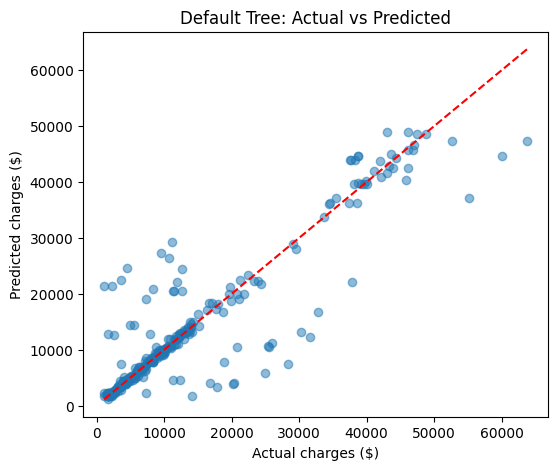

In [60]:
# True vs predicted
plt.figure(figsize=(6, 5))
plt.scatter(y_test_i, pred_test, alpha=0.5)
plt.plot([y_test_i.min(), y_test_i.max()], [y_test_i.min(), y_test_i.max()], "r--")
plt.xlabel("Actual charges ($)"); plt.ylabel("Predicted charges ($)")
plt.title("Default Tree: Actual vs Predicted")
plt.show()

### Interpretation

Encoding:
I converted sex into is_male (1 = male) and smoker into is_smoker (1 = smoker), and one-hot encoded region into three columns (northwest, southeast, southwest), with northeast as the baseline. The training and test sets have the same 8 columns. No scaling was needed, because decision trees split on thresholds.

Baseline tree (default settings):
- The tree grew to a depth of 18 with 1,069 leaves, which is exactly the number of training people. In other words, every person ended up in their own leaf.
- On the training data, it scored a perfect R² of 1.00 with $0 error, because it memorized every person's charges. This is extreme overfitting.
- On the test data, it scored R² = 0.819, RMSE = $5,769, and MAE = $2,731. On average, its predictions are off by about $2,700, but some errors are much larger, which increases the RMSE.

Actual vs predicted chart:
- Many points lie close to the red line, especially for lower costs, because the main patterns (smoking, age, BMI) are strong.
- However, many points are far from the line. For example, some people with actual charges around $20,000 to $30,000 were predicted at under $10,000, and some with about $5,000 were predicted at over $20,000. Because each leaf represents only one person, a new person is compared to just one similar training person, which can easily give a wrong value.

Next, I will tune the hyperparameters to make the tree simpler and more reliable.

In [61]:
from sklearn.model_selection import KFold

In [62]:
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)

In [63]:
def test_param_reg(param, values, base=None):
    rows = []
    for v in values:
        settings = dict(base or {})
        settings[param] = v
        t = DecisionTreeRegressor(random_state=42, **settings).fit(X_train_ie, y_train_i)
        rows.append({
            param: v,
            "Train R²": round(r2_score(y_train_i, t.predict(X_train_ie)), 3),
            "CV R²": round(cross_val_score(t, X_train_ie, y_train_i, cv=kf5, scoring="r2").mean(), 3),
            "Test R²": round(r2_score(y_test_i, t.predict(X_test_ie)), 3),
            "Test RMSE": round(np.sqrt(mean_squared_error(y_test_i, t.predict(X_test_ie))), 0),
            "Depth": t.get_depth(),
            "Leaves": t.get_n_leaves()
        })
    return pd.DataFrame(rows)


In [64]:
def plot_param_reg(df, param, title):
    labels = ["None" if pd.isna(v) else str(int(v)) if isinstance(v, float) and v.is_integer() else str(v)
              for v in df[param]]
    plt.figure(figsize=(8, 4))
    plt.plot(labels, df["Train R²"], marker="o", label="Train")
    plt.plot(labels, df["CV R²"], marker="o", label="Cross-validation")
    plt.xlabel(param); plt.ylabel("R²"); plt.title(title); plt.legend(); plt.grid(True)
    plt.show()

In [65]:
# 4A: criterion
print("Criterion with max_depth=4:")
print(test_param_reg("criterion", ["squared_error", "friedman_mse", "absolute_error", "poisson"],
                     base={"max_depth": 4}).to_string(index=False))

Criterion with max_depth=4:
     criterion  Train R²  CV R²  Test R²  Test RMSE  Depth  Leaves
 squared_error     0.855  0.830    0.897     4346.0      4      16
  friedman_mse     0.855  0.830    0.897     4346.0      4      16
absolute_error     0.841  0.827    0.898     4331.0      4      16
       poisson     0.855  0.827    0.897     4347.0      4      16


### Interpretation: Criterion

I compared four criteria with max_depth = 4:
- squared_error and friedman_mse gave identical results (cross-validation R² 0.830, test RMSE $4,346).
- absolute_error and poisson were almost the same (cross-validation R² 0.827).

The criterion made almost no difference. Once the tree is limited, all four criteria choose very similar splits, because the strongest patterns (smoking, age, BMI) are clear enough for any method to find. I kept the default, squared_error.

 max_depth  Train R²  CV R²  Test R²  Test RMSE  Depth  Leaves
       1.0     0.599  0.594    0.673     7749.0      1       2
       2.0     0.813  0.799    0.867     4940.0      2       4
       3.0     0.844  0.824    0.893     4435.0      3       8
       4.0     0.855  0.830    0.897     4346.0      4      16
       5.0     0.867  0.829    0.894     4412.0      5      32
       6.0     0.885  0.813    0.870     4890.0      6      63
       8.0     0.934  0.725    0.851     5224.0      8     205
      10.0     0.979  0.657    0.836     5485.0     10     468
       NaN     1.000  0.649    0.819     5769.0     18    1069


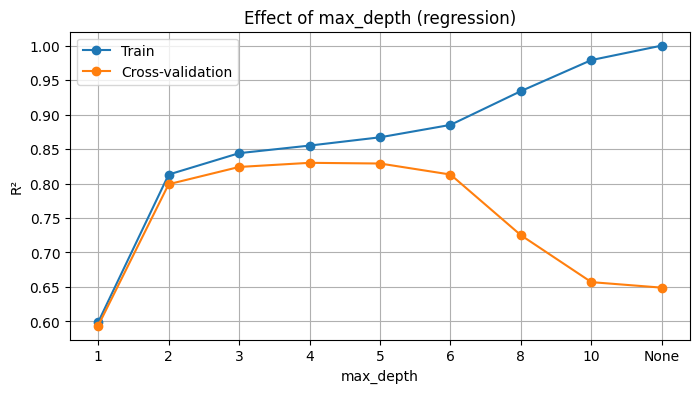

In [66]:
# 4B: max_depth
d_df = test_param_reg("max_depth", [1, 2, 3, 4, 5, 6, 8, 10, None])
print(d_df.to_string(index=False)); plot_param_reg(d_df, "max_depth", "Effect of max_depth (regression)")

### Interpretation: max_depth

- Depth 1 (one question, 2 leaves) already explains about 59% of the variation (cross-validation R² 0.594). This single split is almost certainly on smoking.
- Depth 2 jumps to 0.799, because the tree can add a second question such as age or BMI.
- Cross-validation R² is highest at depth 4 (0.830), with 16 leaves and a test RMSE of $4,346.
- After depth 5, cross-validation R² drops sharply (0.725 at depth 8 and 0.649 with no limit), while training R² keeps rising to 1.00. The growing gap shows overfitting.

Depth 4 gives the best balance: simple enough to generalize, but deep enough to capture the main patterns.

 min_samples_leaf  Train R²  CV R²  Test R²  Test RMSE  Depth  Leaves
                1     1.000  0.649    0.819     5769.0     18    1069
                2     0.950  0.743    0.835     5503.0     15     463
                5     0.903  0.802    0.870     4884.0     15     169
               10     0.880  0.822    0.885     4603.0     12      83
               20     0.866  0.828    0.891     4476.0      8      42
               30     0.859  0.828    0.893     4429.0      7      27
               50     0.851  0.816    0.894     4405.0      5      16
               80     0.832  0.816    0.881     4675.0      4       9


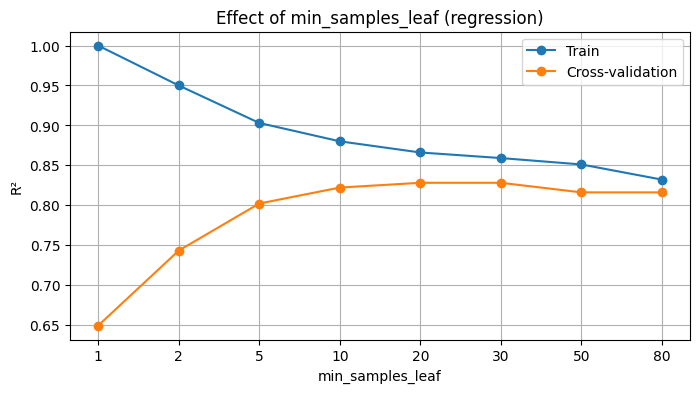

In [67]:
# 4C: min_samples_leaf
l_df = test_param_reg("min_samples_leaf", [1, 2, 5, 10, 20, 30, 50, 80])
print(l_df.to_string(index=False)); plot_param_reg(l_df, "min_samples_leaf", "Effect of min_samples_leaf (regression)")

### Interpretation: min_samples_leaf

- With the default (1), every person gets their own leaf (1,069 leaves), and cross-validation R² is only 0.649.
- Raising the minimum quickly improves the model: 0.802 at 5, 0.822 at 10, and the best results at 20 and 30 (0.828).
- At min_samples_leaf = 30, the tree has only 27 leaves and a test RMSE of $4,429, much better than the default ($5,769).
- At 50 and 80, cross-validation R² drops slightly (0.816), because the leaves become too large to show finer differences between people.

Requiring at least 20 to 30 people per leaf makes each prediction an average of a group of similar people, which is more reliable than using one person.

 min_samples_split  Train R²  CV R²  Test R²  Test RMSE  Depth  Leaves
                 2     1.000  0.649    0.819     5769.0     18    1069
                 5     0.960  0.710    0.831     5573.0     16     412
                10     0.933  0.760    0.845     5338.0     14     208
                20     0.898  0.788    0.864     4996.0     12      99
                40     0.880  0.815    0.869     4913.0     10      52
                80     0.865  0.825    0.888     4537.0      9      27
               120     0.836  0.816    0.880     4694.0      6      14


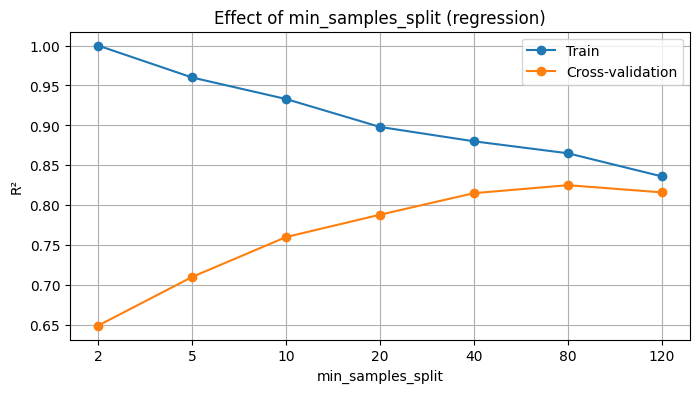

In [68]:
# 4D: min_samples_split
s_df = test_param_reg("min_samples_split", [2, 5, 10, 20, 40, 80, 120])
print(s_df.to_string(index=False)); plot_param_reg(s_df, "min_samples_split", "Effect of min_samples_split (regression)")

### Interpretation: min_samples_split

- With the default (2), the tree overfits (cross-validation R² 0.649).
- Increasing the minimum steadily improves cross-validation R², reaching the best result at 80 (0.825) with 27 leaves and a test RMSE of $4,537.
- At 120, it drops slightly (0.816), because the tree becomes too simple.

Unlike Part 1, min_samples_split worked almost as well as min_samples_leaf here. With more training data (1,069 people), large minimum values still leave enough room for useful splits.

## Step 5: Pruning, GridSearchCV, and the Final Tuned Tree

Task was destroyed but it is pending!
task: <Task pending name='Task-264' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-265' coro=<Kernel.shell_main() running at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\re\_parser.py:168: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  def __getitem__(self, index):
Task was destroyed but it is pending!
task: <Task pending name='Task-265' coro=<Kernel.shell_main() running at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_

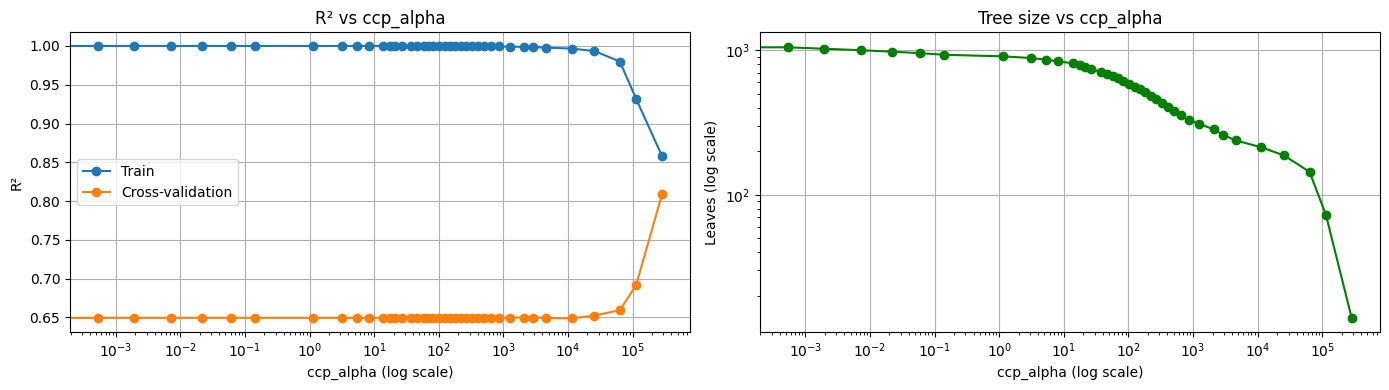

Best ccp_alpha: 286,220 | CV R²: 0.809 | Leaves: 14


In [69]:
# 5A: ccp_alpha pruning path
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(X_train_ie, y_train_i)
alphas = np.unique(np.quantile(path.ccp_alphas, np.linspace(0, 0.99, 40)))

rows = []
for a in alphas:
    t = DecisionTreeRegressor(random_state=42, ccp_alpha=a).fit(X_train_ie, y_train_i)
    rows.append({"ccp_alpha": a,
                 "Train R²": r2_score(y_train_i, t.predict(X_train_ie)),
                 "CV R²": cross_val_score(t, X_train_ie, y_train_i, cv=kf5, scoring="r2").mean(),
                 "Leaves": t.get_n_leaves()})
alpha_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(alpha_df["ccp_alpha"], alpha_df["Train R²"], marker="o", label="Train")
axes[0].plot(alpha_df["ccp_alpha"], alpha_df["CV R²"], marker="o", label="Cross-validation")
axes[0].set_xscale("log"); axes[0].set_xlabel("ccp_alpha (log scale)"); axes[0].set_ylabel("R²")
axes[0].set_title("R² vs ccp_alpha"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(alpha_df["ccp_alpha"], alpha_df["Leaves"], marker="o", color="green")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("ccp_alpha (log scale)"); axes[1].set_ylabel("Leaves (log scale)")
axes[1].set_title("Tree size vs ccp_alpha"); axes[1].grid(True)
plt.tight_layout(); plt.show()

best_a = alpha_df.loc[alpha_df["CV R²"].idxmax()]
print(f"Best ccp_alpha: {best_a['ccp_alpha']:,.0f} | CV R²: {best_a['CV R²']:.3f} | Leaves: {int(best_a['Leaves'])}")


### Interpretation: Post-Pruning with ccp_alpha

- Small ccp_alpha values (up to about 10,000) barely changed the tree: it kept around 1,000 leaves, training R² stayed at 1.00, and cross-validation R² stayed at about 0.65 (overfitting).
- The alpha values are very large because this is a regression tree measured in dollars squared (MSE), so the penalty has to be large to remove branches.
- Pruning only started to help above about 100,000. The best alpha I tested was 286,220, which reduced the tree to just 14 leaves and raised cross-validation R² to 0.809.

Post-pruning greatly improved the default tree, but the best pre-pruned trees (for example, max_depth = 4 with cross-validation R² 0.830) performed slightly better.

In [70]:
# 5B: GridSearchCV
param_grid_r = {
    "criterion": ["squared_error", "absolute_error"],
    "max_depth": [3, 4, 5, 6, None],
    "min_samples_leaf": [5, 10, 20, 30, 50],
    "min_samples_split": [2, 20, 80]
}
grid_r = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid_r, cv=kf5, scoring="r2", n_jobs=-1)
grid_r.fit(X_train_ie, y_train_i)
print("\nCombinations tested:", len(grid_r.cv_results_["params"]))
print("Best settings:", grid_r.best_params_)
print("Best CV R²:", round(grid_r.best_score_, 3))


Combinations tested: 150
Best settings: {'criterion': 'absolute_error', 'max_depth': 6, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV R²: 0.835


### Interpretation: GridSearchCV

I tested 150 combinations of criterion, max_depth, min_samples_leaf, and min_samples_split with 5-fold cross-validation.

Best settings: criterion = absolute_error, max_depth = 6, min_samples_leaf = 5, min_samples_split = 2.
Best cross-validation R²: 0.835, the highest of all my experiments.

Interestingly, the best criterion was absolute_error. With this criterion, each leaf predicts the median charges of its group instead of the average. Because charges are right-skewed (a few people have very high costs), the median is less affected by these extreme values, which helps the tree make more reliable predictions for typical people.

       Model    R²  RMSE ($)  MAE ($)        MSE  Leaves
Default tree 0.819    5769.0   2731.0 33281525.0    1069
  Tuned tree 0.888    4535.0   1853.0 20569779.0      59
Tuned tree - Train R²: 0.853


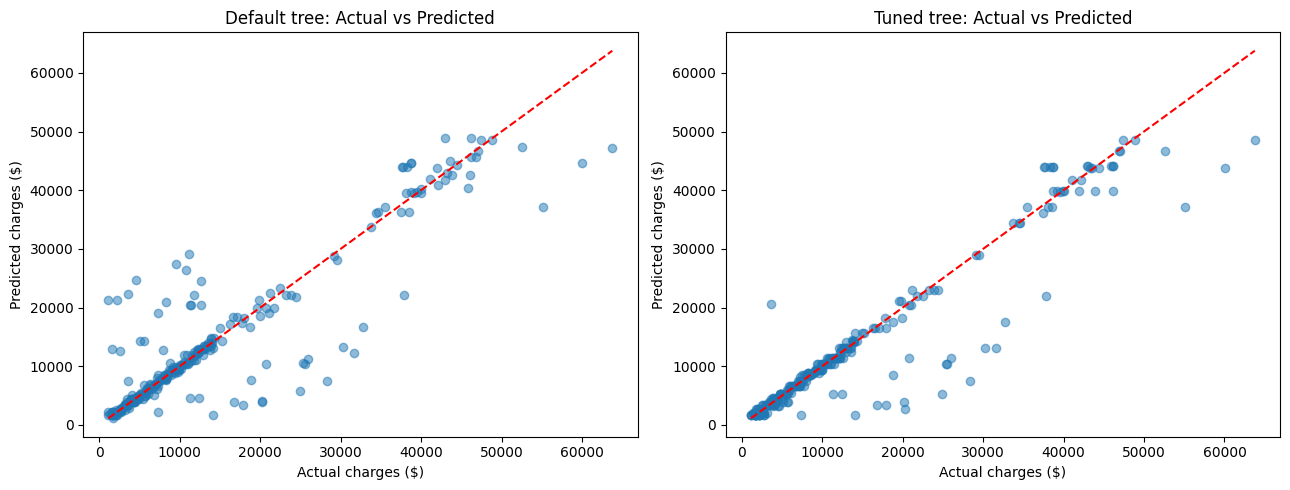

In [71]:
final_reg = grid_r.best_estimator_
pred_final = final_reg.predict(X_test_ie)

summary = pd.DataFrame([
    {"Model": "Default tree", **reg_scores(y_test_i, pred_test), "Leaves": reg_default.get_n_leaves()},
    {"Model": "Tuned tree", **reg_scores(y_test_i, pred_final), "Leaves": final_reg.get_n_leaves()}
])
print(summary.to_string(index=False))
print("Tuned tree - Train R²:", round(r2_score(y_train_i, final_reg.predict(X_train_ie)), 3))

# True vs predicted: default vs tuned
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, name in [(axes[0], pred_test, "Default tree"), (axes[1], pred_final, "Tuned tree")]:
    ax.scatter(y_test_i, pred, alpha=0.5)
    ax.plot([y_test_i.min(), y_test_i.max()], [y_test_i.min(), y_test_i.max()], "r--")
    ax.set_xlabel("Actual charges ($)"); ax.set_ylabel("Predicted charges ($)")
    ax.set_title(f"{name}: Actual vs Predicted")
plt.tight_layout(); plt.show()

### Default vs tuned (test set):
- Default tree: R² 0.819, RMSE $5,769, MAE $2,731, with 1,069 leaves.
- Tuned tree: R² 0.888, RMSE $4,535, MAE $1,853, with only 59 leaves.
- The tuned tree's average error (MAE) dropped by about $880, from $2,731 to $1,853, and it uses 18 times fewer leaves.
- The tuned tree's training R² is 0.853, close to its test R² (0.888), so it is no longer overfitting.

Actual vs predicted:
- Compared to the default tree, many of the large random errors have disappeared, and most points are now close to the red line.
- The remaining large errors are mostly people with high actual costs (about $20,000 to $35,000) who were predicted much lower (under $15,000). These are likely people with medical costs caused by factors not in the dataset, such as illnesses or accidents.


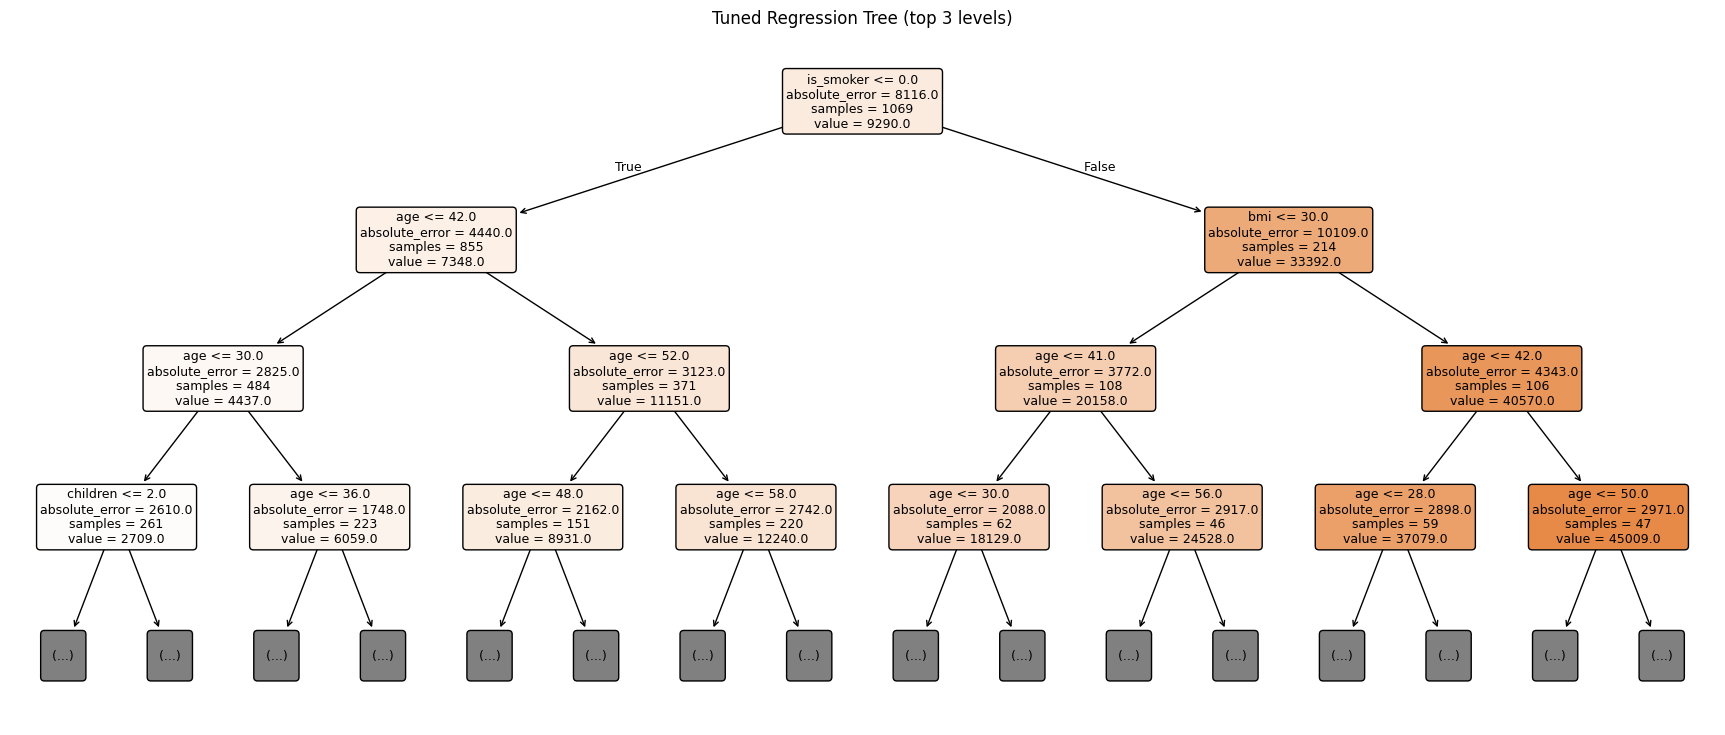

In [72]:
# Tree diagram (top 3 levels, so it's readable)
plt.figure(figsize=(22, 9))
plot_tree(final_reg, feature_names=X_train_ie.columns, filled=True, rounded=True,
          fontsize=9, max_depth=3, precision=0)
plt.title("Tuned Regression Tree (top 3 levels)")
plt.show()

### The tree diagram (top 3 levels):
- The first question is is_smoker, which splits the 1,069 people into 855 non-smokers (median charges $7,348) and 214 smokers (median charges $33,392). This matches the EDA, where smoking was the biggest factor.
- For non-smokers, the next questions are all about age (42, 30, and 52). Costs rise steadily with age, from a median of $4,437 for those 30 or younger to $12,240 for those over 58.
- For smokers, the next question is bmi <= 30, exactly the threshold I saw in the EDA. Smokers with BMI 30 or below have a median of $20,158, while smokers with BMI above 30 have a median of $40,570. Older smokers with high BMI (over 50) have the highest median, about $45,009.

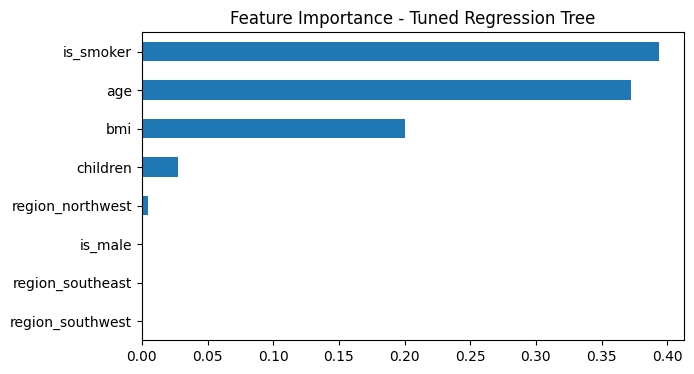

In [73]:
# Feature importance
imp = pd.Series(final_reg.feature_importances_, index=X_train_ie.columns).sort_values()
imp[imp > 0].plot(kind="barh", figsize=(7, 4), title="Feature Importance - Tuned Regression Tree")
plt.show()

### Feature importance:
- is_smoker (about 0.39), age (about 0.37), and bmi (about 0.20) together make up about 96% of the importance.
- children has a small role, and sex and region have almost no effect.

The tree learned clear, readable rules, such as "smoker AND BMI above 30 → very high costs", which matches the patterns found in the EDA.

## Part 2 Summary

- The default regression tree memorized the training data (1,069 leaves, one per person) and reached a test R² of 0.819 with an RMSE of $5,769.
- Limiting max_depth, min_samples_leaf, and min_samples_split all reduced overfitting. GridSearchCV found the best combination: absolute_error, max_depth = 6, min_samples_leaf = 5 (cross-validation R² 0.835).
- The tuned tree reached a test R² of 0.888, RMSE of $4,535, and MAE of $1,853, with only 59 leaves.
- Smoking, age, and BMI drive medical costs. The tree found the same BMI 30 threshold for smokers that I saw in the EDA.

# Report

## Approach
I built decision trees for two health problems: classifying patients as sick or healthy (UCI Heart Disease, 303 patients) and predicting medical insurance costs (Medical Cost Personal dataset, 1,337 people). For both, I split the data 80/20 before exploring it, explored only the training data, prepared the features using training data only, trained a default tree, and then tested hyperparameters one at a time before combining them with GridSearchCV. I judged settings mainly by 5-fold cross-validation, and used the test set only for the final check.

## Key findings
- Both default trees overfit badly. The classification tree reached 100% training accuracy with 48 leaves, and the regression tree created one leaf for every training person (1,069 leaves).
- Controlling tree size was the most important tuning step. min_samples_leaf and max_depth gave the biggest improvements in both parts.
- Classification: the tuned tree (gini, max_depth = 4, min_samples_leaf = 10) improved test accuracy from 73.8% to 86.9%, with 13 leaves instead of 48. thal, chest pain type, and the number of blocked vessels were the most important features.
- Regression: the tuned tree (absolute_error, max_depth = 6, min_samples_leaf = 5) improved test R² from 0.819 to 0.888 and reduced the average error from $2,731 to $1,853. Smoking, age, and BMI were the most important features.
- The choice of criterion (Gini vs entropy, or squared vs absolute error) mattered much less than the size limits, once the trees were controlled.
- max_features and class_weight did not help on the heart disease data, which is already balanced.
- Post-pruning with ccp_alpha also reduced overfitting, but pre-pruning gave slightly better results in both parts.

## Reflections
- The experiments made the theory concrete. With no limits, the trees behaved exactly like my "sick vs healthy rooms" example: they kept splitting until every room held one person, which is memorizing rather than learning.
- Simpler trees were not only more accurate on new data but also easy to read. For example, the regression tree's rules ("smoker AND BMI above 30 → very high costs") could be explained to anyone.
- The heart disease dataset is small, so cross-validation scores varied by 1% to 2% between settings, and I avoided over-interpreting small differences.
- Possible improvements: try Random Forest or Gradient Boosting, which combine many trees to reduce errors further, and use repeated cross-validation for more stable comparisons.